# Soil moisture at Washington stations

Every soil moisture report from [Synoptic](https://synopticdata.com) stations in Washington for October 2026, staged with `gaia stage synoptic -v soil_moisture` as a CF ragged array (see [Synoptic stations](../docs/datasets.md#synoptic)).

- Soil moisture is volumetric water content, in m³ m⁻³.
- A sensor Synoptic places at a depth is named for it (`soil_moisture_10cm`). Sensors without a depth are `soil_moisture`, `soil_moisture_set_2`, ….
- Staging needs a `SYNOPTIC_TOKEN`. Free Synoptic accounts can only request about the last year, so move the window forward when rerunning.

The AOI, [washington-aoi.geojson](https://github.com/gaia-hazlab/gaia-cli/blob/main/examples/washington-aoi.geojson), is the state's outline as one polygon, with the islands merged into it (from US Census boundaries, via [usstatesgeojson](https://github.com/glynnbird/usstatesgeojson)).

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import xarray as xr

from gaia_cli import stations

In [2]:
aoi = "washington-aoi.geojson"
out = "scratch/wa-soil"  # gitignored

In [3]:
!gaia stage synoptic -i {aoi} -s 2026-10-01 -e 2026-10-29 -v soil_moisture -o {out} --overwrite

15:01:55 [   2.0s] stagefile: Wrote scratch/wa-soil/stage.yaml
15:01:55 [   2.0s] runner: synoptic: loading (2026-10-01T00:00:00/2026-10-30T00:00:00, read as 2026-09-30T00:00:00/2026-10-31T00:00:00)
15:01:55 [   2.0s] datasets.synoptic: querying station metadata from https://api.synopticdata.com/v2
15:01:55 [   2.1s] datasets.synoptic: found 24 stations with soil_moisture in the AOI
15:01:55 [   2.1s] datasets.synoptic: fetching timeseries for 24 station(s)
15:01:56 [   3.2s] io: Writing Zarr to scratch/wa-soil/wa-soil.zarr
15:01:56 [   3.3s] io: Saved scratch/wa-soil/wa-soil.zarr
15:01:56 [   3.3s] io: Wrote STAC item scratch/wa-soil/wa-soil.json
15:01:56 [   3.3s] runner: Done


In [4]:
ds = xr.open_dataset(f"{out}/wa-soil.zarr", engine="zarr", group="stations/synoptic")
ds

<xarray.Dataset> Size: 341kB
Dimensions:              (geometry: 8, obs: 4725, node: 8)
Coordinates:
    lat                  (geometry) float64 64B ...
    lon                  (geometry) float64 64B ...
    station              (geometry) StringDType() 128B ...
    time                 (obs) datetime64[ns] 38kB ...
    spatial_ref          int64 8B ...
Dimensions without coordinates: geometry, obs, node
Data variables: (12/15)
    elevation            (geometry) float64 64B ...
    geometry_container   float64 8B ...
    name                 (geometry) StringDType() 128B ...
    network_id           (geometry) StringDType() 128B ...
    row_size             (geometry) int64 64B ...
    soil_moisture        (obs) float64 38kB ...
    ...                   ...
    soil_moisture_20cm   (obs) float64 38kB ...
    soil_moisture_50cm   (obs) float64 38kB ...
    soil_moisture_5cm    (obs) float64 38kB ...
    soil_moisture_set_2  (obs) float64 38kB ...
    x                    (node) float64 64B ...
    y                    (node) float64 64B ...
Attributes:
    title:               Synoptic Data station observations
    description:         Every report of precipitation and other requested va...
    license:             other
    gaia:license-note:   Synoptic redistributes data from many station networ...
    providers:           [{'name': 'Synoptic Data PBC', 'roles': ['host', 'pr...
    version:             v2
    processing:lineage:  every report kept as a CF contiguous ragged array; p...
    links:               [{'rel': 'via', 'href': 'https://api.synopticdata.co...
    start_datetime:      2026-09-30T00:00:00Z
    end_datetime:        2026-10-30T23:41:00Z

## Stations and sensors

Each station's sensors, and how many reports each one made in the window.

In [5]:
def depth(v):
    """A sensor's depth in cm, from its name; sensors without one sort last."""
    name = v.removeprefix("soil_moisture_")
    return float(name[:-2]) if name.endswith("cm") else float("inf")


def label(v):
    return "no depth" if v == "soil_moisture" else v.removeprefix("soil_moisture_")


df = stations.to_dataframe(ds)
soil = sorted((c for c in df if c.startswith("soil_moisture")), key=depth)
reports = df.groupby("station", sort=False)[soil].count()

sites = ds.xvec.decode_cf()[["name", "network_id", "elevation"]].xvec.to_geopandas()
sites["station"] = ds.station.values
sites["sensors"] = [", ".join(label(c) for c in soil if reports.loc[s, c]) for s in sites.station]
sites["reports"] = reports.max(axis=1).values
sites.drop(columns="geometry")

,name,network_id,elevation,station,sensors,reports
0,Paradise,37,1645.9200,PVC54,"no depth, set_2",744
1,LIND #1,29,499.8720,LDDW1,no depth,338
2,OHANAPECOSH,2,594.3600,OHAW1,no depth,725
3,Sunrise Base,37,1953.7680,SUN64,"no depth, set_2",718
4,HOZOMEEN,2,518.1600,HZCW1,no depth,736
5,COOK FARM FIELD D,29,831.1896,COOW1,no depth,337
6,Maywood,263,427.0248,C3MYD,"5cm, 10cm, 15cm, 20cm, 50cm, 100cm",744
7,Stampede,263,704.0880,C3STP,"5cm, 10cm, 15cm, 20cm, 50cm, 100cm",383


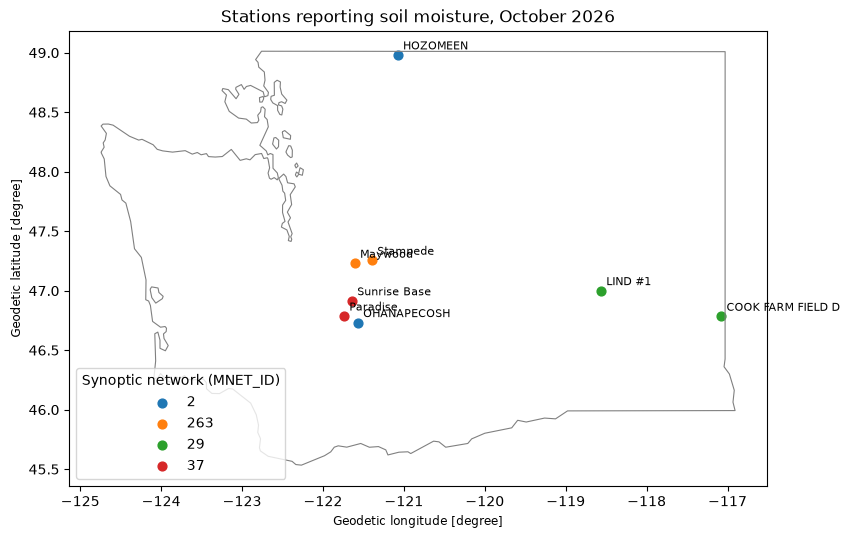

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
gpd.read_file(aoi).boundary.plot(ax=ax, color="0.5", lw=0.8)
sites.plot(ax=ax, column="network_id", categorical=True, legend=True, markersize=40,
           legend_kwds={"title": "Synoptic network (MNET_ID)", "loc": "lower left"})
for _, s in sites.iterrows():
    ax.annotate(s["name"], (s.geometry.x, s.geometry.y), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_title("Stations reporting soil moisture, October 2026")
ax.set_aspect(1 / 0.68)  # roughly equal distances at 47°N

## Profiles

CW3E's Green River stations measure at six depths, from 5 cm to 1 m. `stations.to_grid` puts each station's reports on an hourly grid.

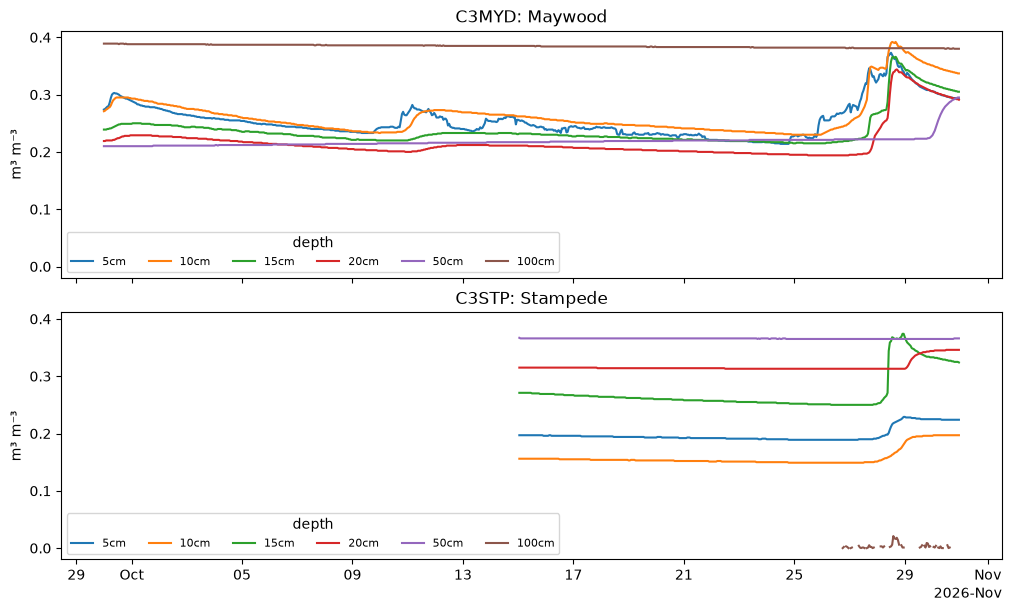

In [7]:
hourly = stations.to_grid(ds, freq="1h").swap_dims(geometry="station")
depths = [v for v in soil if depth(v) < float("inf")]
profiled = [s for s in sites.station if reports.loc[s, depths].any()]

fig, axes = plt.subplots(len(profiled), 1, figsize=(10, 3 * len(profiled)), sharex=True, sharey=True, layout="constrained")
for ax, s in zip(axes if len(profiled) > 1 else [axes], profiled):
    for v in depths:
        if reports.loc[s, v]:
            hourly[v].sel(station=s).plot(ax=ax, label=label(v))
    ax.set_title(f"{s}: {hourly.name.sel(station=s).item()}")
    ax.set_ylabel("m³ m⁻³")
    ax.set_xlabel("")
    ax.legend(title="depth", ncols=6, fontsize=8)

## Stations without depths

The other networks (NWAC, RAWS, SCAN) don't tell Synoptic at which depth their sensors sit. Sensors, calibrations and soils differ, so compare wetting and drying between stations rather than absolute values.

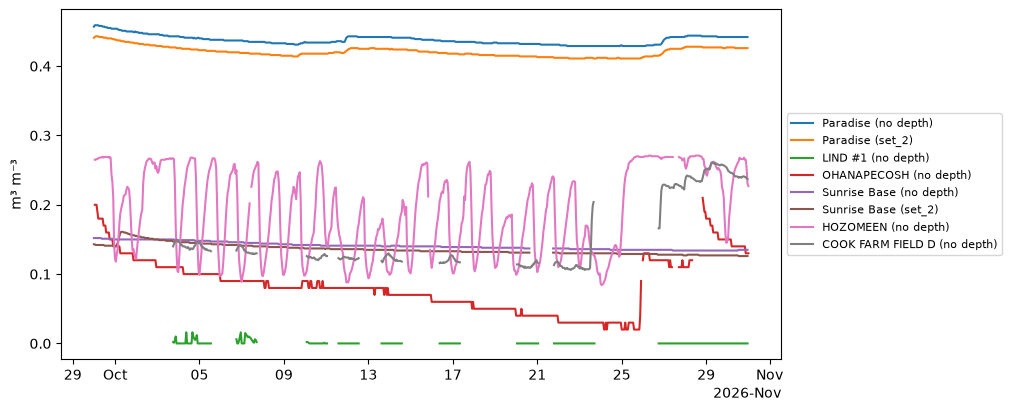

In [8]:
others = [v for v in soil if v not in depths]
unprofiled = [s for s in sites.station if s not in profiled]

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for s in unprofiled:
    for v in others:
        if reports.loc[s, v]:
            hourly[v].sel(station=s).plot(ax=ax, label=f"{hourly.name.sel(station=s).item()} ({label(v)})")
ax.set_ylabel("m³ m⁻³")
ax.set_xlabel("")
ax.set_title("")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))